# 03 · Finding groups of destination airports (clustering)

**What we group:** the 118 destination airports, by their **delay pattern**: how late flights to that airport usually leave New York, how often they are late or cancelled, and how that changes through the day.

**Why:** one answer ("is this destination reliable?") is too coarse and 118 answers are too many. A few clear *types* of destination let the agency act differently for each type, and later (notebook 05) the type becomes a column the models can use.

As in notebook 02, we use the **training months only (January to September)** to describe the destinations, so the test months stay untouched.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

common.require_processed("flights_clean.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

## 1. Choose what to describe each destination with
For every destination we build 7 numbers from the training months:

| Column | Meaning |
|---|---|
| `avg_dep_delay` | average departure delay in minutes (flights that left) |
| `share_late` | share of departed flights that left more than 15 minutes late |
| `share_cancelled` | share of scheduled flights that were cancelled |
| `delay_night`, `delay_morning`, `delay_afternoon`, `delay_evening` | average delay for flights scheduled 0-5 h, 6-11 h, 12-17 h and 18-23 h |

**Two choices, explained**
- **Delays are capped at 3 hours (180 minutes)** when averaged. A single 30-hour overnight delay would otherwise define a small airport. The share of late flights is not affected by the cap.
- **Destinations with fewer than 100 flights in these 9 months are not grouped.** Their averages rest on too few flights. They form their own label, "Rare destinations".

A time band with no flights to that destination takes the destination's overall average, so no gap reaches the clustering.

In [2]:
MIN_FLIGHTS = 100
flights = pd.read_parquet(common.PROC / "flights_clean.parquet")
t = flights[flights["part"] != "test"]
dep = t[t["dep_delay"].notna()].copy()
dep["capped"] = dep["dep_delay"].clip(upper=180)
dep["band"] = pd.cut(dep["hour"], [-1, 5, 11, 17, 24], labels=["night", "morning", "afternoon", "evening"])

dest = pd.DataFrame({"flights": t.groupby("dest").size()})
dest["avg_dep_delay"] = dep.groupby("dest")["capped"].mean()
dest["share_late"] = dep.groupby("dest")["dep_delay"].apply(lambda s: (s > common.LATE_MINUTES).mean())
dest["share_cancelled"] = t.groupby("dest")["cancelled"].mean()
by_band = dep.groupby(["dest", "band"], observed=True)["capped"].mean().unstack()
for band in ["night", "morning", "afternoon", "evening"]:
    dest[f"delay_{band}"] = by_band[band].reindex(dest.index).fillna(dest["avg_dep_delay"])
FEATURES = ["avg_dep_delay", "share_late", "share_cancelled", "delay_night", "delay_morning", "delay_afternoon", "delay_evening"]
assert len(dest) == 118 and dest[FEATURES].notna().all().all()

grouped = dest[dest["flights"] >= MIN_FLIGHTS].copy()
print(f"{len(dest)} destinations | {len(grouped)} have {MIN_FLIGHTS}+ flights and will be grouped | {len(dest) - len(grouped)} are rare")
print(grouped[FEATURES].describe().round(2).loc[["mean", "std", "min", "max"]].to_string())

118 destinations | 109 have 100+ flights and will be grouped | 9 are rare
      avg_dep_delay  share_late  share_cancelled  delay_night  delay_morning  delay_afternoon  delay_evening
mean          13.31        0.23             0.04        11.32           7.09            15.48          20.23
std            8.76        0.09             0.02         9.54           8.81            15.57          10.28
min            0.93        0.09             0.00       -11.00          -6.84            -7.00           2.16
max           51.39        0.61             0.12        51.39          44.85           134.00          52.27


## 2. Scale the columns
Delay is in minutes and shares are between 0 and 1. Without scaling, minutes would drown out the shares. `StandardScaler` puts every column on the same footing (average 0, spread 1).

In [3]:
X = StandardScaler().fit_transform(grouped[FEATURES])
assert not np.isnan(X).any()
print("matrix for k-means:", X.shape, "| no missing values")

matrix for k-means: (109, 7) | no missing values


## 3. How many groups? Try k-means with k = 2 to 10
- **Elbow:** the total distance of destinations to their group centre (*inertia*) always falls as k grows. We look for the k after which it stops falling quickly.
- **Silhouette:** between -1 and 1, how clearly destinations sit in their own group and not between groups. Higher is better.
- **Common sense:** a group must be a *type* of destination, not one single airport.

In [4]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=common.SEED).fit(X)
    rows.append(dict(k=k, inertia=round(km.inertia_, 1), silhouette=round(silhouette_score(X, km.labels_), 3),
                     sizes=" / ".join(str(s) for s in sorted(np.bincount(km.labels_), reverse=True))))
selection = pd.DataFrame(rows)
common.REPORTS.mkdir(parents=True, exist_ok=True)
selection.to_csv(common.REPORTS / "03_k_selection.csv", index=False)
selection["inertia_drop"] = selection["inertia"].diff(-1).round(1)
print(selection.to_string(index=False))

 k  inertia  silhouette                                     sizes  inertia_drop
 2    464.2       0.580                                   98 / 11         137.1
 3    327.1       0.366                               64 / 39 / 6          54.6
 4    272.5       0.357                           60 / 42 / 6 / 1          32.3
 5    240.2       0.253                      44 / 29 / 29 / 6 / 1          26.8
 6    213.4       0.267                 39 / 38 / 14 / 11 / 6 / 1          25.4
 7    188.0       0.256             35 / 27 / 25 / 14 / 6 / 1 / 1          24.1
 8    163.9       0.293          42 / 38 / 13 / 8 / 5 / 1 / 1 / 1          13.3
 9    150.6       0.254      32 / 26 / 25 / 7 / 7 / 5 / 5 / 1 / 1          14.7
10    135.9       0.259 28 / 23 / 22 / 16 / 8 / 5 / 4 / 1 / 1 / 1           NaN


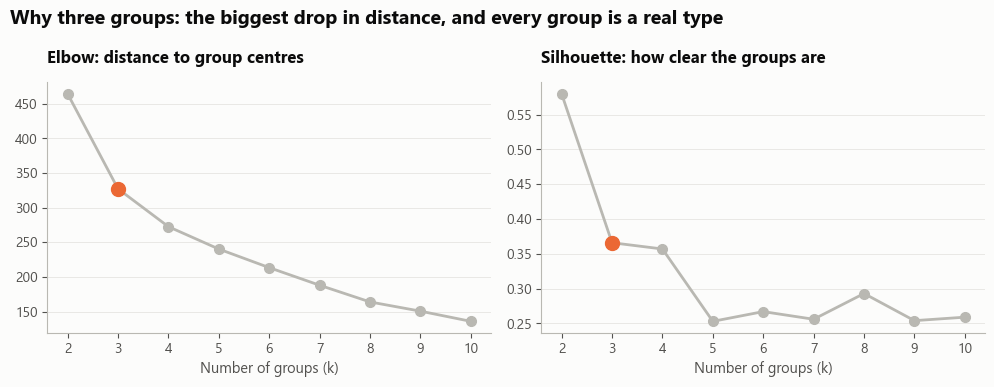

In [5]:
K = 3
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, col, title in zip(axes, ["inertia", "silhouette"], ["Elbow: distance to group centres", "Silhouette: how clear the groups are"]):
    ax.plot(selection["k"], selection[col], color=viz.GREY, linewidth=2, marker="o", markersize=7)
    ax.plot(K, selection.loc[selection["k"] == K, col], color=viz.ORANGE, marker="o", markersize=10, linestyle="none")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Number of groups (k)")
fig.suptitle("Why three groups: the biggest drop in distance, and every group is a real type", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
chart_k = viz.save_figure(fig, "03_k_selection.png")
plt.show()

**Why k = 3**
- **Elbow:** the biggest drop in inertia comes from k = 2 to k = 3; after that each extra group buys much less.
- **Silhouette:** k = 2 scores higher, but it only splits off a handful of extreme airports from everyone else (see its sizes in the table), which hides the difference between the other destinations. k = 3 keeps a clear structure and splits the main body in two types the agency can treat differently.
- **Common sense:** at k = 4 and above, a group of a single airport appears, which is not a type. With k = 3 the smallest group still has 6 destinations.

## 4. Fit the 3 groups, describe and name each one

In [6]:
km = KMeans(n_clusters=K, n_init=10, random_state=common.SEED).fit(X)
grouped["label"] = km.labels_
prof = grouped.groupby("label")[["flights", "avg_dep_delay"]].mean()
thin_label = prof["avg_dep_delay"].idxmax()                    # the group with the longest delays
hub_label = prof["flights"].drop(thin_label).idxmax()           # of the rest, the one with the most flights
steady_label = [l for l in prof.index if l not in (thin_label, hub_label)][0]
assert prof.loc[steady_label, "avg_dep_delay"] == prof["avg_dep_delay"].min(), "the steady group must have the shortest delays"
assert (grouped["label"] == thin_label).sum() <= 10 and prof.loc[thin_label, "flights"] < 600, "the thin group should be a handful of low-volume routes"

NAMES = {steady_label: (0, "Steady regional routes"), hub_label: (1, "Afternoon build-up routes"), thin_label: (2, "Thin routes with long delays")}
grouped["group_id"] = grouped["label"].map(lambda l: NAMES[l][0])
grouped["group_name"] = grouped["label"].map(lambda l: NAMES[l][1])
n_days = t["sched_dep_dt"].dt.date.nunique()
grouped["flights_per_day"] = grouped["flights"] / n_days
print(grouped.groupby(["group_id", "group_name"])[["flights", "flights_per_day"] + FEATURES].mean().round(2).to_string())
print("\nthe small group, destination by destination (flights per day over", n_days, "days):")
print(grouped[grouped["group_id"] == 2][["flights", "flights_per_day", "avg_dep_delay", "share_late"]].round(2).sort_values("flights", ascending=False).to_string())

                                       flights  flights_per_day  avg_dep_delay  share_late  share_cancelled  delay_night  delay_morning  delay_afternoon  delay_evening
group_id group_name                                                                                                                                                    
0        Steady regional routes        2351.69             8.61           8.29        0.18             0.04         7.75           3.94             8.11          13.82
1        Afternoon build-up routes     4576.08            16.76          17.29        0.27             0.03        12.62           8.40            24.67          27.44
2        Thin routes with long delays   263.67             0.97          40.96        0.53             0.03        40.96          32.14            34.45          41.80

the small group, destination by destination (flights per day over 273 days):
      flights  flights_per_day  avg_dep_delay  share_late
dest                    

**What the numbers say**
- **Steady regional routes:** the short delays (about 8 minutes on average), the fewest late flights, and mornings that are almost always on time. It is the steadiest for delays, but not for cancellations: its cancellation share is a bit higher than for the other types (4.2% against 2.5% for the afternoon build-up routes).
- **Afternoon build-up routes:** the group is defined by its *pattern*, not by size. Mornings are fine, but delays pile up after noon: the afternoon and evening averages are about three times the morning one. It holds many of the big airports (ORD, MCO, ATL, MIA, LAX, FLL) but not all of them (BOS and CLT are steady), and also some small ones.
- **Thin routes with long delays:** only 6 destinations, each with about one flight a day or less. Their flights are late far more often, and because there is little choice of flights, one delay leaves clients with few alternatives. All their delay readings come from a single time of day, so treat the group as "one daily flight per route" and not as a statement about the airport itself.

**Rare destinations** (fewer than 100 flights) are kept out of the grouping and labelled as such.

In [7]:
rare = dest[dest["flights"] < MIN_FLIGHTS]
labels = pd.concat([
    grouped[["group_id", "group_name"]],
    pd.DataFrame({"group_id": -1, "group_name": "Rare destinations (too few flights to judge)"}, index=rare.index),
]).rename_axis("dest").reset_index().sort_values("dest").reset_index(drop=True)
assert labels["dest"].is_unique and len(labels) == 118
common.PROC.mkdir(parents=True, exist_ok=True)
labels.to_parquet(common.PROC / "destination_groups.parquet", index=False)
print(labels["group_name"].value_counts().to_string())

group_name
Steady regional routes                          64
Afternoon build-up routes                       39
Rare destinations (too few flights to judge)     9
Thin routes with long delays                     6


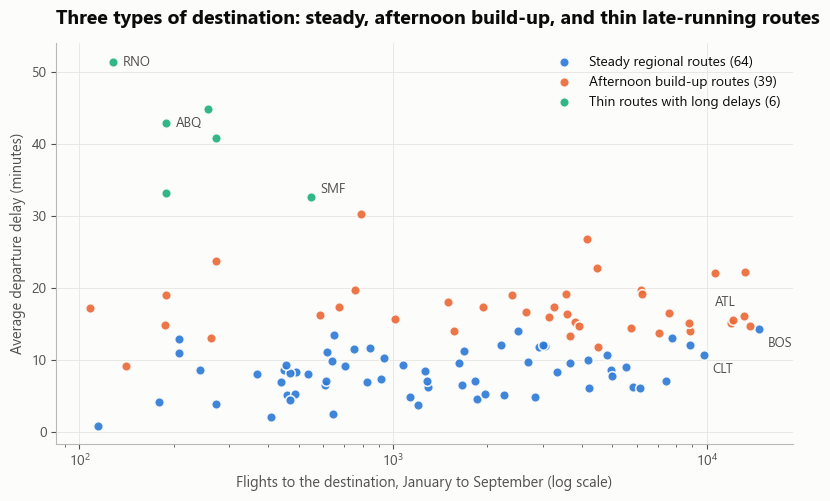

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = {0: viz.BLUE, 1: viz.ORANGE, 2: viz.AQUA}
for gid, grp in grouped.groupby("group_id"):
    ax.scatter(grp["flights"], grp["avg_dep_delay"], s=48, color=colors[gid], alpha=0.9, edgecolor=viz.SURFACE, linewidth=1.2,
               label=f"{grp['group_name'].iloc[0]} ({len(grp)})")
ax.set_xscale("log")
ax.set_xlabel("Flights to the destination, January to September (log scale)")
ax.set_ylabel("Average departure delay (minutes)")
ax.grid(axis="x")
for d_, offset, ha in [("ATL", (-6, 7), "right"), ("BOS", (6, -13), "left"), ("CLT", (6, -13), "left"), ("SMF", (7, 3), "left"), ("RNO", (7, -3), "left"), ("ABQ", (7, -3), "left")]:
    ax.annotate(d_, (grouped.loc[d_, "flights"], grouped.loc[d_, "avg_dep_delay"]), xytext=offset, ha=ha, textcoords="offset points", fontsize=9.5, color=viz.INK_2)
ax.legend(loc="upper right")
ax.set_title("Three types of destination: steady, afternoon build-up, and thin late-running routes")
chart_g = viz.save_figure(fig, "03_groups.png")
plt.show()

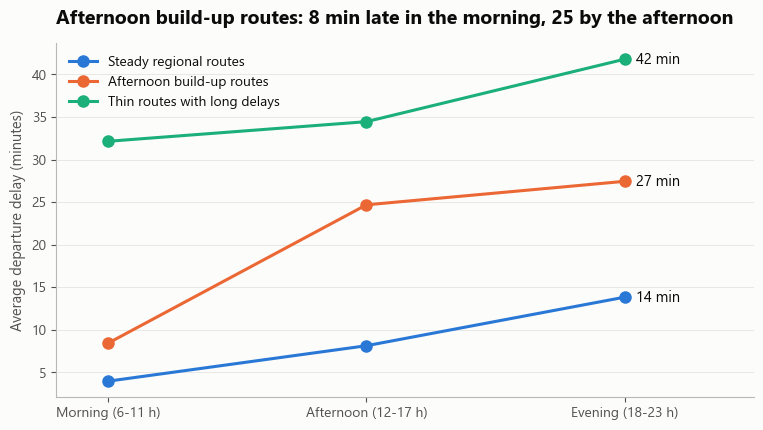

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
bands = ["delay_morning", "delay_afternoon", "delay_evening"]
x = np.arange(3)
means = grouped.groupby("group_id")[bands].mean()
for gid in [0, 1, 2]:
    ax.plot(x, means.loc[gid], color=colors[gid], linewidth=2.2, marker="o", markersize=8, label=grouped.loc[grouped["group_id"] == gid, "group_name"].iloc[0])
    ax.annotate(f"{means.loc[gid].iloc[-1]:.0f} min", (2, means.loc[gid].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=10.5)
ax.set_xticks(x); ax.set_xticklabels(["Morning (6-11 h)", "Afternoon (12-17 h)", "Evening (18-23 h)"])
ax.set_xlim(-0.2, 2.5)
ax.set_ylabel("Average departure delay (minutes)")
ax.legend(loc="upper left")
ax.set_title(f"Afternoon build-up routes: {means.loc[1, 'delay_morning']:.0f} min late in the morning, {means.loc[1, 'delay_afternoon']:.0f} by the afternoon")
chart_t = viz.save_figure(fig, "03_time_of_day.png")
plt.show()

## 5. What the business should do differently for each group

In [10]:
ACTIONS = {
    0: "Shortest delays, but cancellations are a little more common than on the other routes, so a client with a tight connection still needs a backup. No special warning unless the earlier-flight check (notebook 02) shows the plane is already running late.",
    1: "Recommend morning departures. For afternoon and evening flights, leave a longer connection time, and warn clients earlier.",
    2: "Tell clients at booking that one delay leaves few alternatives. Offer flexible tickets, and rebook early when the flight shows signs of delay.",
    -1: "No conclusion is possible. Treat these destinations one by one.",
}
rows = []
for gid, grp in labels.groupby("group_id"):
    name = grp["group_name"].iloc[0]
    d_ = dest.loc[grp["dest"]]
    examples = ", ".join(d_.sort_values("flights", ascending=False).index[:6])
    if gid == -1:
        typical = f"{len(d_)} destinations, {int(d_['flights'].sum()):,} flights in total in 9 months (under {MIN_FLIGHTS} each)"
    else:
        w = d_["flights"]
        typical = (f"{len(d_)} destinations, {int(w.sum()):,} flights; average delay {d_['avg_dep_delay'].mean():.0f} min; "
                   f"{d_['share_late'].mean():.0%} of flights late; {d_['share_cancelled'].mean():.1%} cancelled; "
                   f"delay by time of day: morning {d_['delay_morning'].mean():.0f}, afternoon {d_['delay_afternoon'].mean():.0f}, evening {d_['delay_evening'].mean():.0f} min")
    rows.append(dict(group_id=gid, group_name=name, size=len(d_), flights=int(d_["flights"].sum()), typical=typical, action=ACTIONS[gid], examples=examples))
summary = pd.DataFrame(rows).sort_values("group_id", ascending=False).reset_index(drop=True)
summary.to_csv(common.REPORTS / "03_groups.csv", index=False)
for r in summary.itertuples():
    print(f"{r.group_name}  [{r.size} destinations]\n  Typical: {r.typical}\n  Examples: {r.examples}\n  Do: {r.action}\n")

Thin routes with long delays  [6 destinations]
  Typical: 6 destinations, 1,582 flights; average delay 41 min; 53% of flights late; 3.4% cancelled; delay by time of day: morning 32, afternoon 34, evening 42 min
  Examples: SMF, ONT, PSE, ABQ, SJC, RNO
  Do: Tell clients at booking that one delay leaves few alternatives. Offer flexible tickets, and rebook early when the flight shows signs of delay.

Afternoon build-up routes  [39 destinations]
  Typical: 39 destinations, 178,467 flights; average delay 17 min; 27% of flights late; 2.5% cancelled; delay by time of day: morning 8, afternoon 25, evening 27 min
  Examples: ORD, MCO, ATL, MIA, LAX, FLL
  Do: Recommend morning departures. For afternoon and evening flights, leave a longer connection time, and warn clients earlier.

Steady regional routes  [64 destinations]
  Typical: 64 destinations, 150,508 flights; average delay 8 min; 18% of flights late; 4.2% cancelled; delay by time of day: morning 4, afternoon 8, evening 14 min
  Examples

## 6. Saved for the next notebooks
`data/processed/destination_groups.parquet` holds the group of every destination (`group_id` 0, 1, 2, or -1 for rare destinations). Notebook 05 adds it as a column; notebook 04 reports metrics by group; notebook 07 uses it to choose an action for each group.